In [ ]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("SuperMarket Analysis.csv")
#df = pd.read_csv("../data/SuperMarket_Analysis.csv")
# First 5 rows
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [ ]:
# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

# Data types and non-null values
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

Rows: 1000
Columns: 17

Column Names:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Sales', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Sales                    1

,Unit price,Quantity,Tax 5%,Sales,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000



Missing Values:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Sales                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

Duplicate Rows: 0


In [ ]:
# Create a working copy
df_clean = df.copy()

# Check the copy
df_clean.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [ ]:
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df_clean.columns.tolist())

['invoice_id', 'branch', 'city', 'customer_type', 'gender', 'product_line', 'unit_price', 'quantity', 'tax_5%', 'sales', 'date', 'time', 'payment', 'cogs', 'gross_margin_percentage', 'gross_income', 'rating']


In [ ]:
df_clean["date"] = pd.to_datetime(
    df_clean["date"],
    format="%m/%d/%Y"
)

print(df_clean["date"].head())
print(df_clean["date"].dtype)

0   2019-01-05
1   2019-03-08
2   2019-03-03
3   2019-01-27
4   2019-02-08
Name: date, dtype: datetime64[ns]
datetime64[ns]


In [ ]:
df_clean["time"] = pd.to_datetime(
    df_clean["time"],
    format="%I:%M:%S %p"
).dt.time

print(df_clean["time"].head())

0    13:08:00
1    10:29:00
2    13:23:00
3    20:33:00
4    10:37:00
Name: time, dtype: object


In [ ]:
print("Negative Unit Price:",
      (df_clean["unit_price"] < 0).sum())

print("Negative Quantity:",
      (df_clean["quantity"] < 0).sum())

print("Negative Sales:",
      (df_clean["sales"] < 0).sum())

print("Negative COGS:",
      (df_clean["cogs"] < 0).sum())

print("Negative Gross Income:",
      (df_clean["gross_income"] < 0).sum())

print("Invalid Rating:",
      ((df_clean["rating"] < 0) | (df_clean["rating"] > 10)).sum())

Negative Unit Price: 0
Negative Quantity: 0
Negative Sales: 0
Negative COGS: 0
Negative Gross Income: 0
Invalid Rating: 0


In [ ]:
categorical_columns = [
    "branch",
    "city",
    "customer_type",
    "gender",
    "product_line",
    "payment"
]

for col in categorical_columns:
    print(f"\n{col.upper()}")
    print(df_clean[col].value_counts())


BRANCH
branch
Alex     340
Cairo    332
Giza     328
Name: count, dtype: int64

CITY
city
Yangon       340
Mandalay     332
Naypyitaw    328
Name: count, dtype: int64

CUSTOMER_TYPE
customer_type
Member    565
Normal    435
Name: count, dtype: int64

GENDER
gender
Female    571
Male      429
Name: count, dtype: int64

PRODUCT_LINE
product_line
Fashion accessories       178
Food and beverages        174
Electronic accessories    170
Sports and travel         166
Home and lifestyle        160
Health and beauty         152
Name: count, dtype: int64

PAYMENT
payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64


In [ ]:
df_clean["calculated_sales"] = (
    df_clean["unit_price"] * df_clean["quantity"]
    + df_clean["tax_5%"]
)

difference = (
    df_clean["sales"] - df_clean["calculated_sales"]
).abs()

print("Maximum difference:",
      difference.max())

print("Rows with mismatch:",
      (difference > 0.01).sum())

Maximum difference: 1.1368683772161603e-13
Rows with mismatch: 0


In [ ]:
df_clean["month"] = df_clean["date"].dt.month  #3.1

df_clean["month_name"] = df_clean["date"].dt.month_name()

df_clean[["date", "month", "month_name"]].head()

,date,month,month_name
0,2019-01-05,1,January
1,2019-03-08,3,March
2,2019-03-03,3,March
3,2019-01-27,1,January
4,2019-02-08,2,February


In [ ]:
df_clean["day"] = df_clean["date"].dt.day

df_clean["day_name"] = df_clean["date"].dt.day_name()

df_clean[["date", "day", "day_name"]].head()

,date,day,day_name
0,2019-01-05,5,Saturday
1,2019-03-08,8,Friday
2,2019-03-03,3,Sunday
3,2019-01-27,27,Sunday
4,2019-02-08,8,Friday


In [ ]:
df_clean["hour"] = df_clean["time"].apply(lambda x: x.hour)

df_clean[["time", "hour"]].head()

,time,hour
0,13:08:00,13
1,10:29:00,10
2,13:23:00,13
3,20:33:00,20
4,10:37:00,10


In [ ]:
def get_time_period(hour):
    if hour < 12:
        return "Morning"
    elif hour < 17:
        return "Afternoon"
    elif hour < 21:
        return "Evening"
    else:
        return "Night"

df_clean["time_period"] = df_clean["hour"].apply(get_time_period)

df_clean[["time", "hour", "time_period"]].head(10)

,time,hour,time_period
0,13:08:00,13,Afternoon
1,10:29:00,10,Morning
2,13:23:00,13,Afternoon
3,20:33:00,20,Evening
4,10:37:00,10,Morning
5,18:30:00,18,Evening
6,14:36:00,14,Afternoon
7,11:38:00,11,Morning
8,17:15:00,17,Evening
9,13:27:00,13,Afternoon


In [ ]:
df_clean["revenue_per_item"] = (
    df_clean["sales"] / df_clean["quantity"]
)

df_clean[[
    "sales",
    "quantity",
    "revenue_per_item"
]].head()

,sales,quantity,revenue_per_item
0,548.9715,7,78.4245
1,80.2200,5,16.0440
2,340.5255,7,48.6465
3,489.0480,8,61.1310
4,634.3785,7,90.6255


In [ ]:
df_clean["profit_margin"] = (
    df_clean["gross_income"] / df_clean["sales"]
) * 100

df_clean[[
    "sales",
    "gross_income",
    "profit_margin"
]].head()

,sales,gross_income,profit_margin
0,548.9715,26.1415,4.761905
1,80.2200,3.8200,4.761905
2,340.5255,16.2155,4.761905
3,489.0480,23.2880,4.761905
4,634.3785,30.2085,4.761905


In [ ]:
print(df_clean.columns.tolist())

['invoice_id', 'branch', 'city', 'customer_type', 'gender', 'product_line', 'unit_price', 'quantity', 'tax_5%', 'sales', 'date', 'time', 'payment', 'cogs', 'gross_margin_percentage', 'gross_income', 'rating', 'calculated_sales', 'month', 'month_name', 'day', 'day_name', 'hour', 'time_period', 'revenue_per_item', 'profit_margin']


In [ ]:
print(df_clean[
    [
        "month_name",
        "day_name",
        "hour",
        "time_period",
        "revenue_per_item",
        "profit_margin"
    ]
].head(10))

  month_name   day_name  hour time_period  revenue_per_item  profit_margin
0    January   Saturday    13   Afternoon           78.4245       4.761905
1      March     Friday    10     Morning           16.0440       4.761905
2      March     Sunday    13   Afternoon           48.6465       4.761905
3    January     Sunday    20     Evening           61.1310       4.761905
4   February     Friday    10     Morning           90.6255       4.761905
5      March     Monday    18     Evening           89.6595       4.761905
6   February     Monday    14   Afternoon           72.2820       4.761905
7   February     Sunday    11     Morning           77.2380       4.761905
8    January   Thursday    17     Evening           38.0730       4.761905
9   February  Wednesday    13   Afternoon           57.5820       4.761905


In [ ]:
total_sales = df_clean["sales"].sum()
total_profit = df_clean["gross_income"].sum()
total_quantity = df_clean["quantity"].sum()
total_transactions = df_clean["invoice_id"].nunique()
average_transaction = df_clean["sales"].mean()
average_rating = df_clean["rating"].mean()

print("Total Sales:", round(total_sales, 2))
print("Total Gross Income:", round(total_profit, 2))
print("Total Quantity Sold:", total_quantity)
print("Total Transactions:", total_transactions)
print("Average Transaction Value:", round(average_transaction, 2))
print("Average Customer Rating:", round(average_rating, 2))

Total Sales: 322966.75
Total Gross Income: 15379.37
Total Quantity Sold: 5510
Total Transactions: 1000
Average Transaction Value: 322.97
Average Customer Rating: 6.97


In [ ]:
product_sales = (  #4.2
    df_clean.groupby("product_line")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print(product_sales)

product_line
Food and beverages        56144.8440
Sports and travel         55122.8265
Electronic accessories    54337.5315
Fashion accessories       54305.8950
Home and lifestyle        53861.9130
Health and beauty         49193.7390
Name: sales, dtype: float64


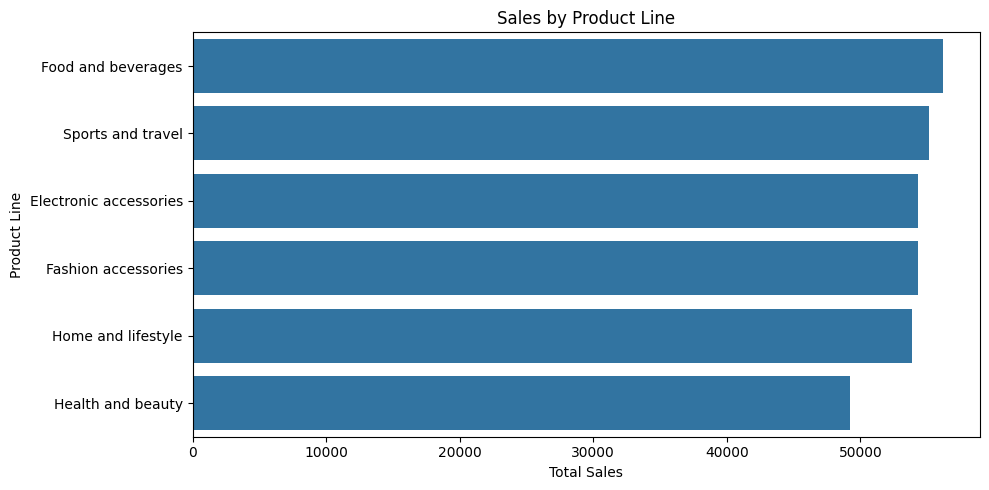

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    x=product_sales.values,
    y=product_sales.index
)

plt.title("Sales by Product Line")
plt.xlabel("Total Sales")
plt.ylabel("Product Line")
plt.tight_layout()
plt.show()

In [ ]:
product_profit = (
    df_clean.groupby("product_line")["gross_income"]
    .sum()
    .sort_values(ascending=False)
)

print(product_profit)

product_line
Food and beverages        2673.5640
Sports and travel         2624.8965
Electronic accessories    2587.5015
Fashion accessories       2585.9950
Home and lifestyle        2564.8530
Health and beauty         2342.5590
Name: gross_income, dtype: float64


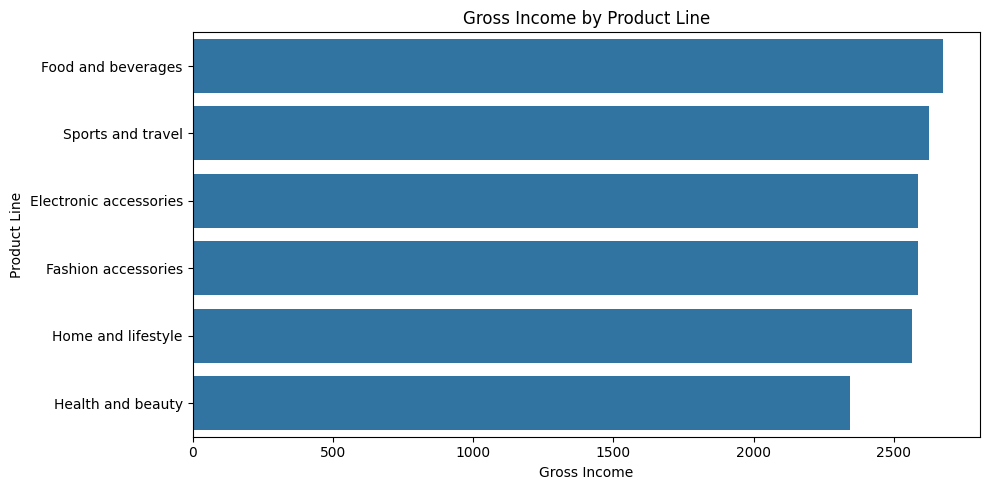

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=product_profit.values,
    y=product_profit.index
)

plt.title("Gross Income by Product Line")
plt.xlabel("Gross Income")
plt.ylabel("Product Line")
plt.tight_layout()
plt.show()

In [ ]:
city_sales = (
    df_clean.groupby("city")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print(city_sales) #4.4

city
Naypyitaw    110568.7065
Yangon       106200.3705
Mandalay     106197.6720
Name: sales, dtype: float64


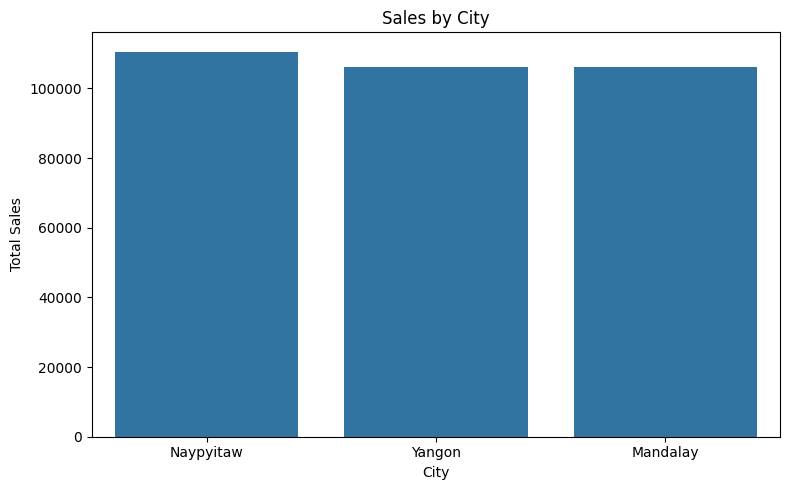

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=city_sales.index,
    y=city_sales.values
)

plt.title("Sales by City")
plt.xlabel("City")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [ ]:
branch_sales = (
    df_clean.groupby("branch")["sales"]
    .sum()
    .sort_values(ascending=False)
)

print(branch_sales)

branch
Giza     110568.7065
Alex     106200.3705
Cairo    106197.6720
Name: sales, dtype: float64


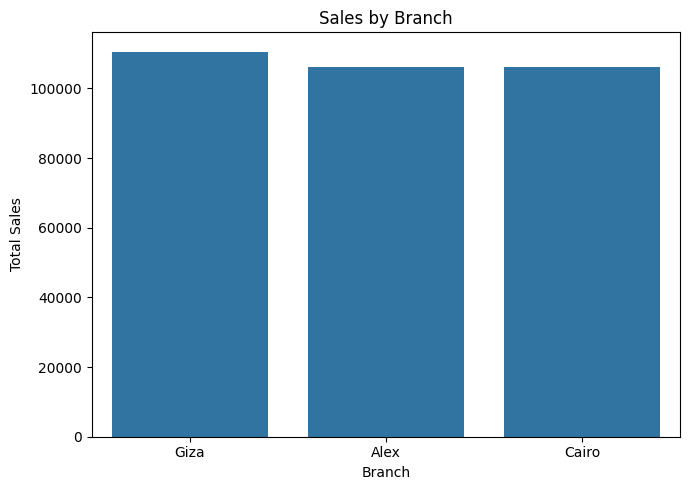

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=branch_sales.index,
    y=branch_sales.values
)

plt.title("Sales by Branch")
plt.xlabel("Branch")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [ ]:
monthly_sales = (
    df_clean.groupby("month_name")["sales"]
    .sum()
)

month_order = ["January", "February", "March"]

monthly_sales = monthly_sales.reindex(month_order)

print(monthly_sales) #4.6

month_name
January     116291.868
February     97219.374
March       109455.507
Name: sales, dtype: float64


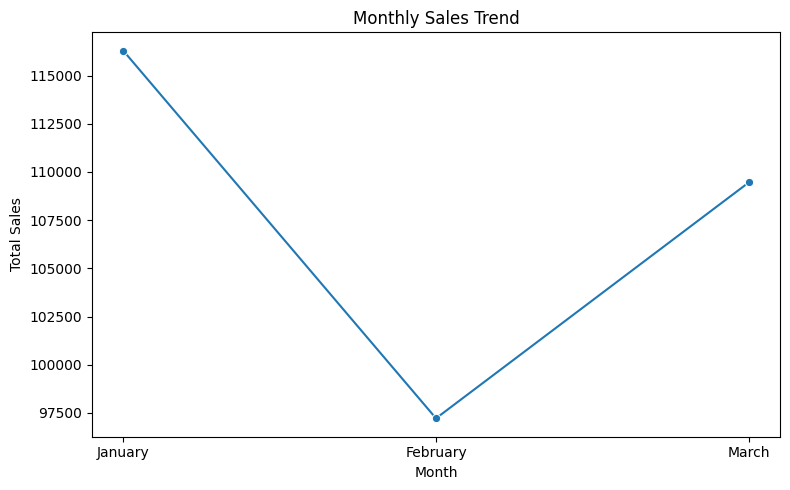

In [ ]:
plt.figure(figsize=(8, 5))

sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [ ]:
customer_analysis = (
    df_clean.groupby("customer_type")
    .agg(
        transactions=("invoice_id", "nunique"),
        total_sales=("sales", "sum"),
        average_sales=("sales", "mean"),
        total_quantity=("quantity", "sum"),
        average_rating=("rating", "mean")
    )
    .round(2)
)

customer_analysis

,transactions,total_sales,average_sales,total_quantity,average_rating
customer_type,,,,,
Member,565,189694.76,335.74,3181,6.92
Normal,435,133271.98,306.37,2329,7.04


In [ ]:
gender_analysis = (
    df_clean.groupby("gender")
    .agg(
        transactions=("invoice_id", "nunique"),
        total_sales=("sales", "sum"),
        average_sales=("sales", "mean"),
        total_quantity=("quantity", "sum"),
        average_rating=("rating", "mean")
    )
    .round(2)
)

gender_analysis

,transactions,total_sales,average_sales,total_quantity,average_rating
gender,,,,,
Female,571,194671.84,340.93,3288,6.96
Male,429,128294.91,299.06,2222,6.99


In [ ]:
product_customer = pd.pivot_table(
    df_clean,
    values="sales",
    index="product_line",
    columns="customer_type",
    aggfunc="sum"
).round(2)

product_customer

customer_type,Member,Normal
product_line,,
Electronic accessories,29194.76,25142.78
Fashion accessories,29926.56,24379.33
Food and beverages,34822.39,21322.46
Health and beauty,31036.82,18156.92
Home and lifestyle,31317.28,22544.63
Sports and travel,33396.95,21725.88


In [ ]:
print("===== CUSTOMER TYPE ANALYSIS =====")
display(customer_analysis)

print("\n===== GENDER ANALYSIS =====")
display(gender_analysis)

print("\n===== PRODUCT LINE × CUSTOMER TYPE =====")
display(product_customer)

===== CUSTOMER TYPE ANALYSIS =====


,transactions,total_sales,average_sales,total_quantity,average_rating
customer_type,,,,,
Member,565,189694.76,335.74,3181,6.92
Normal,435,133271.98,306.37,2329,7.04



===== GENDER ANALYSIS =====


,transactions,total_sales,average_sales,total_quantity,average_rating
gender,,,,,
Female,571,194671.84,340.93,3288,6.96
Male,429,128294.91,299.06,2222,6.99



===== PRODUCT LINE × CUSTOMER TYPE =====


customer_type,Member,Normal
product_line,,
Electronic accessories,29194.76,25142.78
Fashion accessories,29926.56,24379.33
Food and beverages,34822.39,21322.46
Health and beauty,31036.82,18156.92
Home and lifestyle,31317.28,22544.63
Sports and travel,33396.95,21725.88


In [ ]:
payment_analysis = (
    df_clean.groupby("payment")
    .agg(
        transactions=("invoice_id", "nunique"),
        total_sales=("sales", "sum"),
        average_sales=("sales", "mean"),
        total_quantity=("quantity", "sum")
    )
    .round(2)
)

payment_analysis

,transactions,total_sales,average_sales,total_quantity
payment,,,,
Cash,344,112206.57,326.18,1896
Credit card,311,100767.07,324.01,1722
Ewallet,345,109993.11,318.82,1892


In [ ]:
time_analysis = (
    df_clean.groupby("time_period")
    .agg(
        transactions=("invoice_id", "nunique"),
        total_sales=("sales", "sum"),
        average_sales=("sales", "mean"),
        total_quantity=("quantity", "sum")
    )
    .round(2)
)

time_analysis

,transactions,total_sales,average_sales,total_quantity
time_period,,,,
Afternoon,454,148023.34,326.04,2531
Evening,355,113144.60,318.72,1941
Morning,191,61798.81,323.55,1038


In [ ]:
day_analysis = (
    df_clean.groupby("day_name")
    .agg(
        transactions=("invoice_id", "nunique"),
        total_sales=("sales", "sum"),
        average_sales=("sales", "mean")
    )
    .round(2)
    .sort_values("total_sales", ascending=False)
)

day_analysis

,transactions,total_sales,average_sales
day_name,,,
Saturday,164,56120.81,342.20
Tuesday,158,51482.25,325.84
Thursday,138,45349.25,328.62
Sunday,133,44457.89,334.27
Friday,139,43926.34,316.02
Wednesday,143,43731.14,305.81
Monday,125,37899.08,303.19


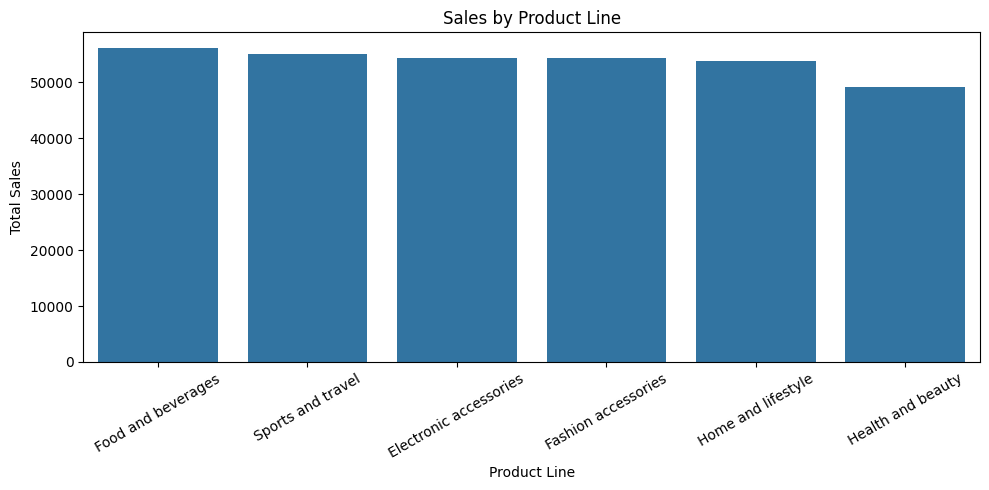

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Sales by Product Line
plt.figure(figsize=(10, 5))
sns.barplot(
    x=product_sales.index,
    y=product_sales.values
)
plt.title("Sales by Product Line")
plt.xlabel("Product Line")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

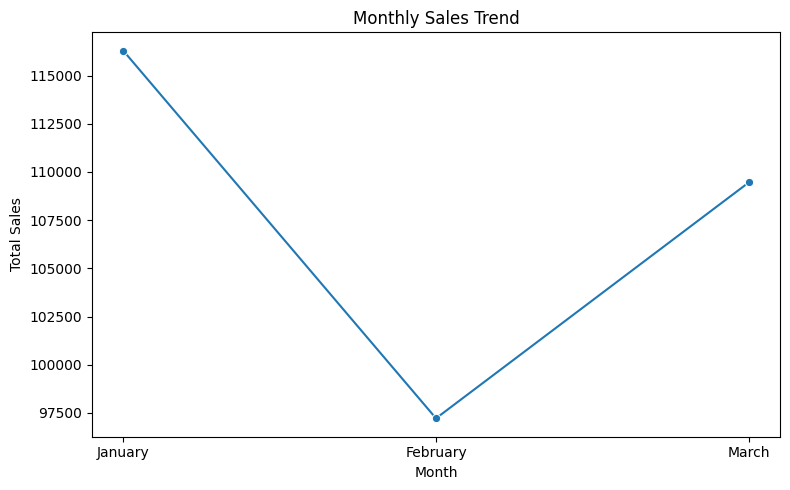

In [ ]:
# 2. Monthly Sales
monthly_sales = (
    df_clean.groupby("month_name")["sales"]
    .sum()
    .reindex(["January", "February", "March"])
)

plt.figure(figsize=(8, 5))
sns.lineplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    marker="o"
)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

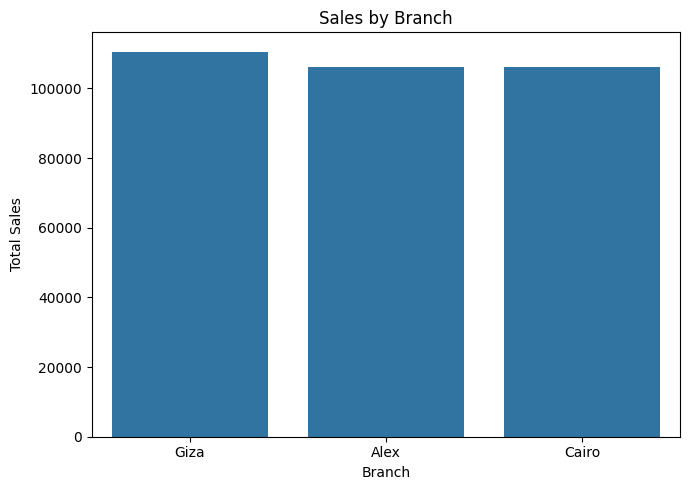

In [ ]:
# 3. Sales by Branch
branch_sales = (
    df_clean.groupby("branch")["sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(7, 5))
sns.barplot(
    x=branch_sales.index,
    y=branch_sales.values
)
plt.title("Sales by Branch")
plt.xlabel("Branch")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [ ]:
import sqlite3

# Create SQLite database
conn = sqlite3.connect("supermarket_sales.db")

# Load cleaned dataset into SQLite
df_clean.to_sql(
    "supermarket_sales",
    conn,
    if_exists="replace",
    index=False
)

print("Database created successfully!")

Database created successfully!


In [ ]:
query = """
SELECT COUNT(*) AS total_rows
FROM supermarket_sales;
"""

pd.read_sql_query(query, conn)

,total_rows
0,1000


In [ ]:
query = """
SELECT
    product_line,
    COUNT(DISTINCT invoice_id) AS transactions,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(AVG(sales), 2) AS average_transaction
FROM supermarket_sales
GROUP BY product_line
ORDER BY total_sales DESC;
"""

product_sql = pd.read_sql_query(query, conn)
product_sql

,product_line,transactions,total_sales,average_transaction
0,Food and beverages,174,56144.84,322.67
1,Sports and travel,166,55122.83,332.07
2,Electronic accessories,170,54337.53,319.63
3,Fashion accessories,178,54305.89,305.09
4,Home and lifestyle,160,53861.91,336.64
5,Health and beauty,152,49193.74,323.64


In [ ]:
query = """
SELECT
    branch,
    city,
    COUNT(DISTINCT invoice_id) AS transactions,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(AVG(sales), 2) AS average_transaction
FROM supermarket_sales
GROUP BY branch, city
ORDER BY total_sales DESC;
"""

branch_sql = pd.read_sql_query(query, conn)
branch_sql

,branch,city,transactions,total_sales,average_transaction
0,Giza,Naypyitaw,328,110568.71,337.10
1,Alex,Yangon,340,106200.37,312.35
2,Cairo,Mandalay,332,106197.67,319.87


In [ ]:
query = """
SELECT
    customer_type,
    COUNT(DISTINCT invoice_id) AS transactions,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(AVG(sales), 2) AS average_transaction,
    SUM(quantity) AS total_quantity,
    ROUND(AVG(rating), 2) AS average_rating
FROM supermarket_sales
GROUP BY customer_type
ORDER BY total_sales DESC;
"""

customer_sql = pd.read_sql_query(query, conn)
customer_sql

,customer_type,transactions,total_sales,average_transaction,total_quantity,average_rating
0,Member,565,189694.76,335.74,3181,6.92
1,Normal,435,133271.98,306.37,2329,7.04


In [ ]:
query = """
SELECT
    strftime('%m', date) AS month,
    CASE strftime('%m', date)
        WHEN '01' THEN 'January'
        WHEN '02' THEN 'February'
        WHEN '03' THEN 'March'
    END AS month_name,
    COUNT(DISTINCT invoice_id) AS transactions,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(AVG(sales), 2) AS average_transaction
FROM supermarket_sales
GROUP BY month
ORDER BY month;
"""

monthly_sql = pd.read_sql_query(query, conn)
monthly_sql

,month,month_name,transactions,total_sales,average_transaction
0,01,January,352,116291.87,330.37
1,02,February,303,97219.37,320.86
2,03,March,345,109455.51,317.26


In [ ]:
query = """
SELECT
    payment,
    COUNT(DISTINCT invoice_id) AS transactions,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(AVG(sales), 2) AS average_transaction,
    SUM(quantity) AS total_quantity
FROM supermarket_sales
GROUP BY payment
ORDER BY total_sales DESC;
"""

payment_sql = pd.read_sql_query(query, conn)
payment_sql

,payment,transactions,total_sales,average_transaction,total_quantity
0,Cash,344,112206.57,326.18,1896
1,Ewallet,345,109993.11,318.82,1892
2,Credit card,311,100767.07,324.01,1722


In [ ]:
query = """
SELECT
    time_period,
    COUNT(DISTINCT invoice_id) AS transactions,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(AVG(sales), 2) AS average_transaction,
    SUM(quantity) AS total_quantity
FROM supermarket_sales
GROUP BY time_period
ORDER BY total_sales DESC;
"""

time_sql = pd.read_sql_query(query, conn)
time_sql

,time_period,transactions,total_sales,average_transaction,total_quantity
0,Afternoon,454,148023.34,326.04,2531
1,Evening,355,113144.60,318.72,1941
2,Morning,191,61798.81,323.55,1038
